In [2]:
%pip install pandas seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import glob
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.rcParams.update({"font.size": 9})
plt.rcParams["figure.figsize"] = (6, 3)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["lines.linewidth"] = 1

In [9]:
serial_df = pd.read_csv('../serial/results.csv')
omp_df = pd.read_csv('../openmp/results.csv')
mpi_df = pd.read_csv('../mpi/results.csv')
cuda_df = pd.read_csv('../cuda/results.csv')

In [3]:
serial_col = "#000000"
omp_col = sns.color_palette("Blues", 6)
mpi_col = sns.color_palette("Reds", 6)
cuda_col = sns.color_palette("Greens", 6)
addn_col = sns.color_palette("Oranges", 6)

In [4]:
ns = np.array(sorted(serial_df["n"].unique()))

In [5]:
ns * np.log2(ns)

array([1.02400000e+04, 2.25280000e+04, 4.91520000e+04, 1.06496000e+05,
       2.29376000e+05, 4.91520000e+05, 1.04857600e+06, 2.22822400e+06,
       4.71859200e+06, 9.96147200e+06, 2.09715200e+07, 4.40401920e+07,
       9.22746880e+07, 1.92937984e+08, 4.02653184e+08, 8.38860800e+08,
       1.74483046e+09])

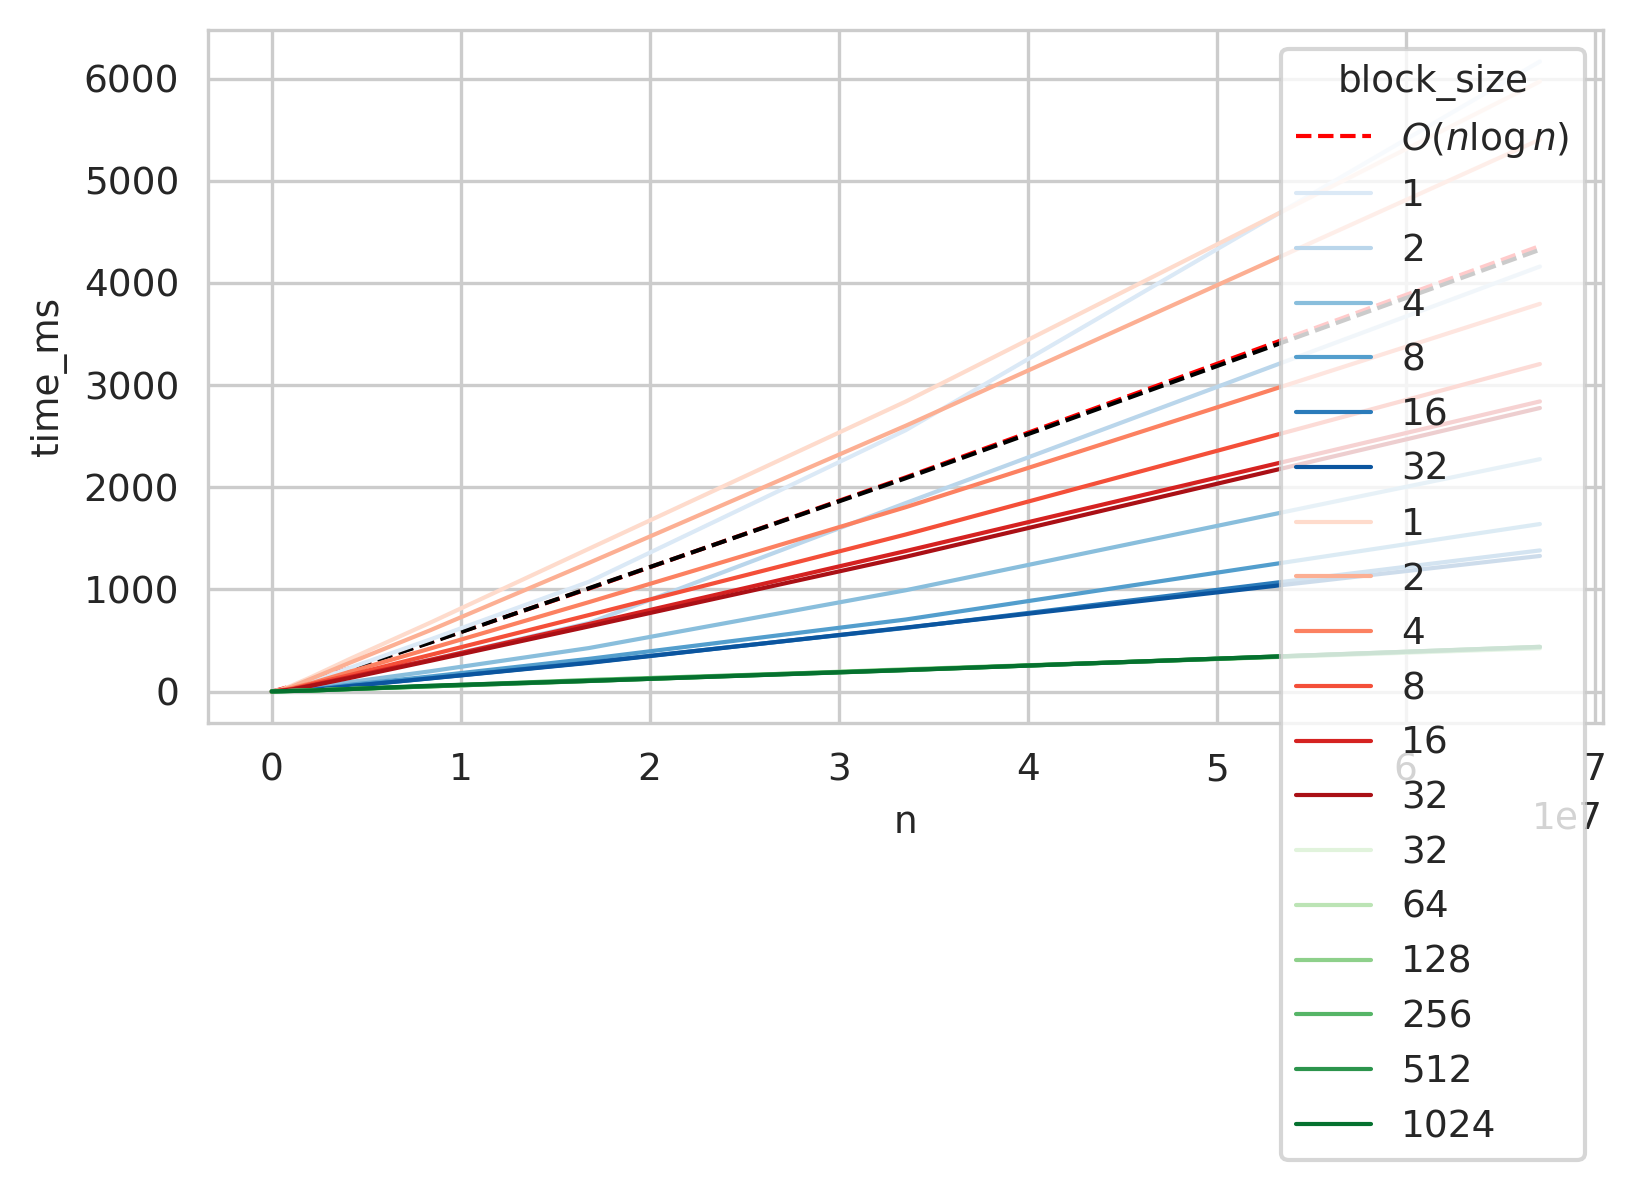

In [10]:
ax = sns.lineplot(x=ns, y=ns * np.log2(ns) * 2.5e-6, color='red', linestyle="--", label="$O(n \\log n)$")
sns.lineplot(ax=ax, data=serial_df, x="n", y="time_ms", color=serial_col, linestyle="--")
sns.lineplot(ax=ax, data=omp_df, x="n", y="time_ms", hue="threads", palette=omp_col)
sns.lineplot(ax=ax, data=mpi_df, x="n", y="time_ms", hue="processes", palette=mpi_col)
sns.lineplot(ax=ax, data=cuda_df, x="n", y="time_ms", hue="block_size", palette=cuda_col)
plt.show()

# OMP

## Strong scaling

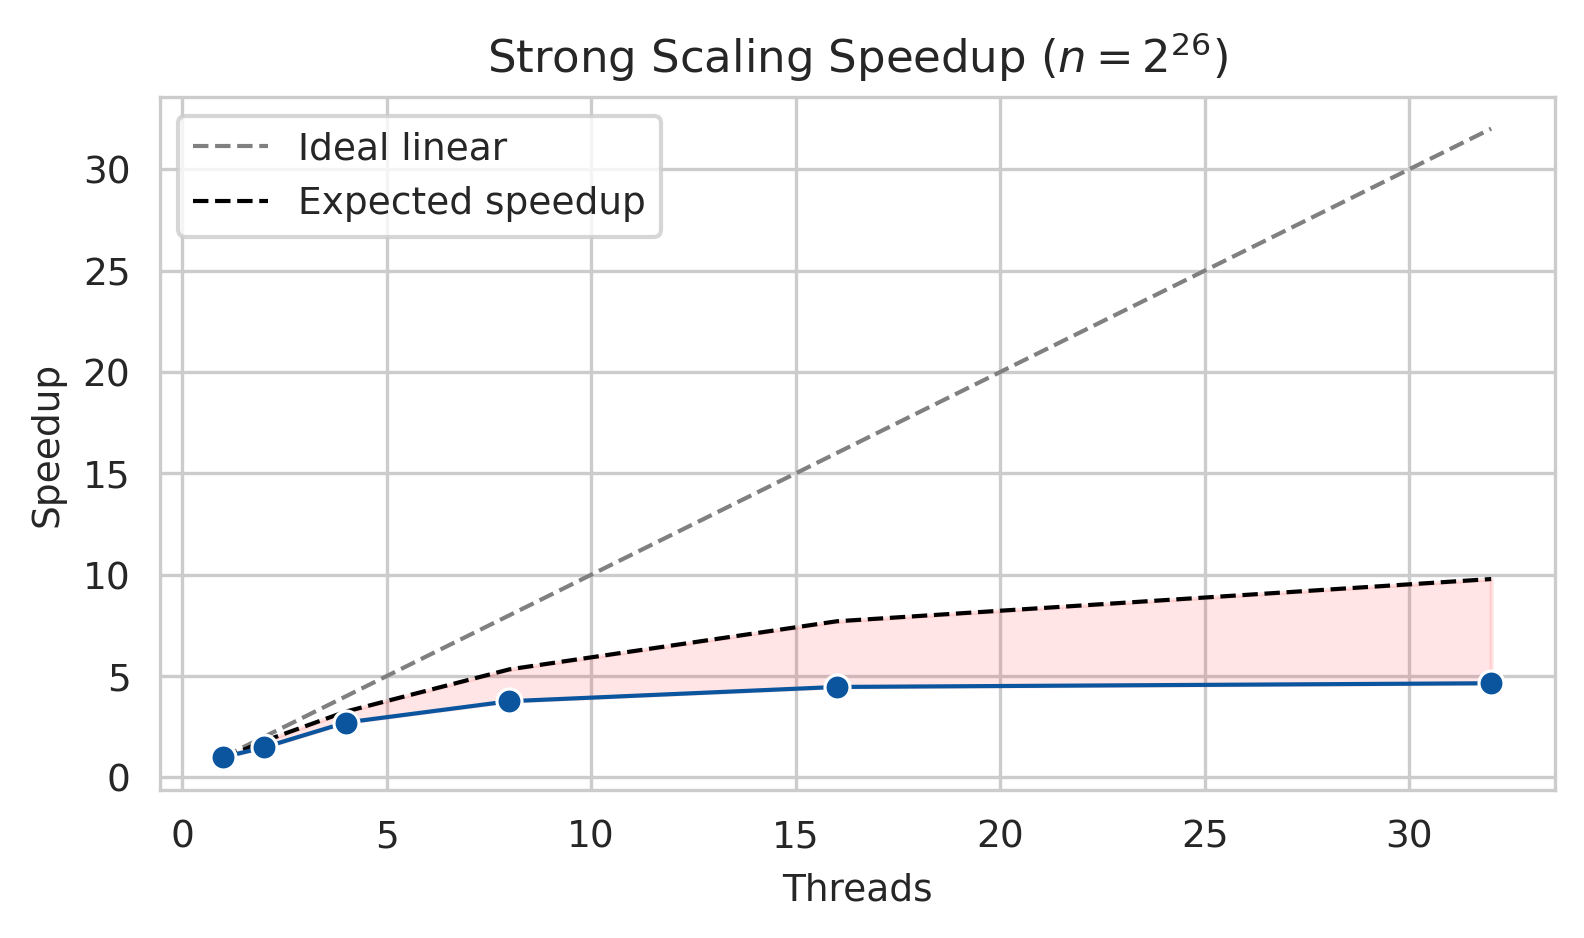

In [30]:
n_to_compare = max(omp_df['n'])
omp_strong_df = omp_df[omp_df["n"] == n_to_compare]
baseline = omp_strong_df[omp_strong_df["threads"] == 1]["time_ms"].values[0]

def strong_scaling(T):
    return (T * np.log2(n_to_compare)) / (np.log2(n_to_compare / T) + 2 * T)

threads = np.array(sorted(omp_strong_df["threads"].unique()))
speedups = [baseline / omp_strong_df[omp_strong_df["threads"] == t]["time_ms"].values[0] for t in threads]

# optional: ideal speedup reference line
plt.plot(threads, threads, linestyle='--', color='gray', label='Ideal linear')
plt.plot(threads, strong_scaling(threads), linestyle='--', color='black', label='Expected speedup')

sns.lineplot(x=threads, y=speedups, marker='o', color=omp_col[-1])

plt.fill_between(x=threads, y1=speedups, y2=strong_scaling(threads), alpha=0.1, color="red")

plt.xlabel("Threads")
plt.ylabel("Speedup")
plt.title(f"Strong Scaling Speedup ($n=2^{{{int(np.log2(n_to_compare))}}}$)")

plt.legend()
plt.show()

## Weak scaling

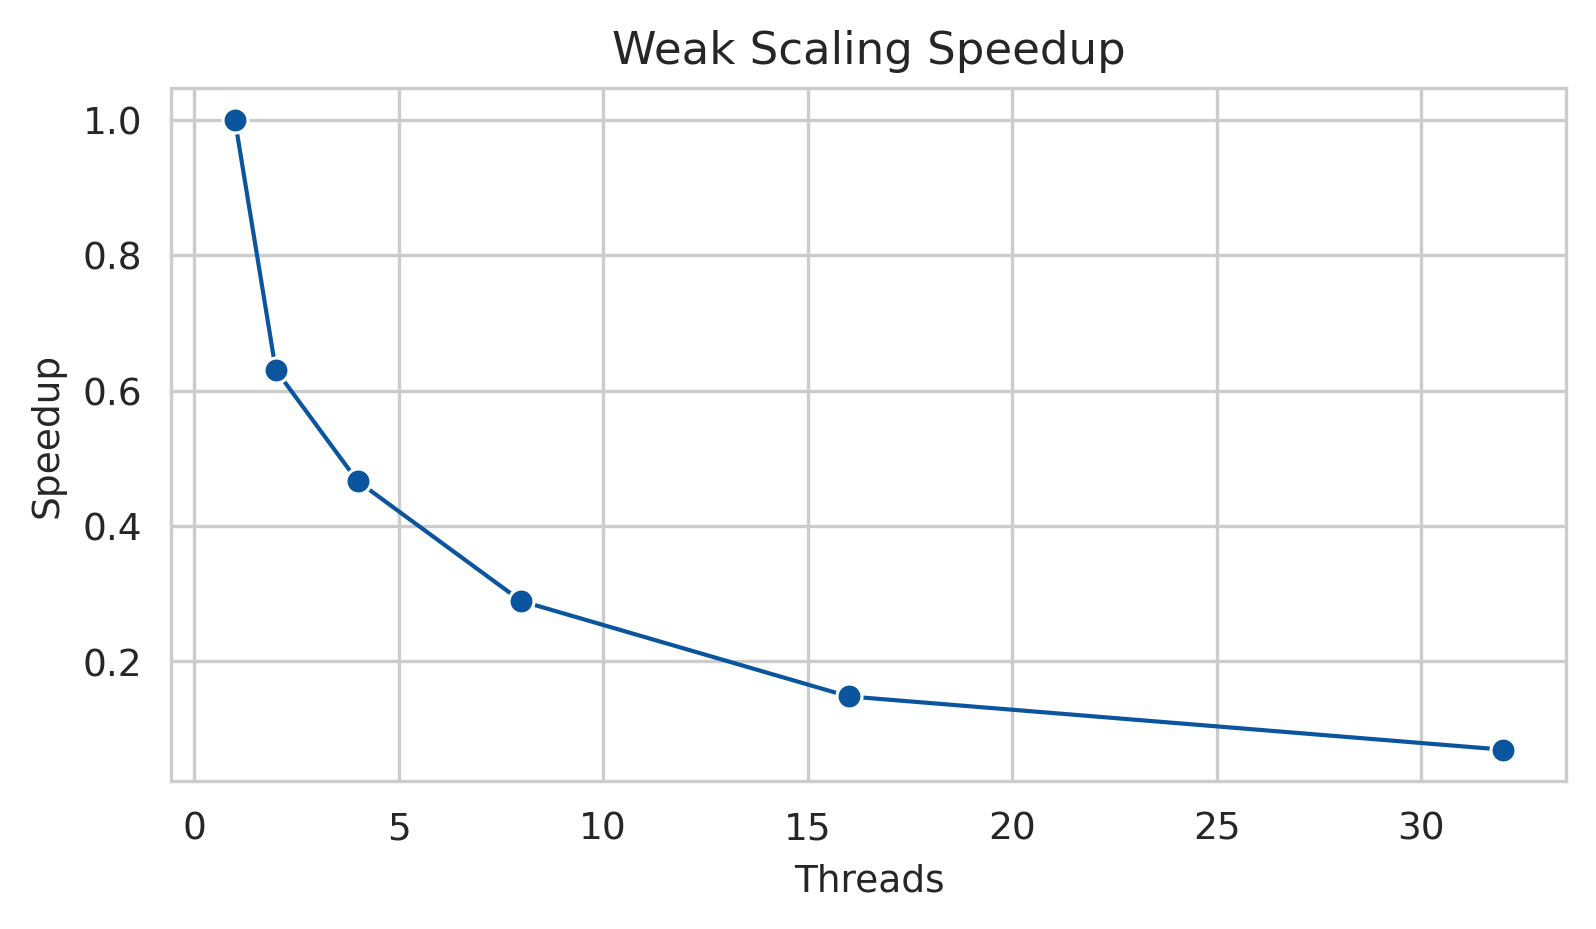

In [31]:
n_per_thread = int(n_to_compare / max(threads))
baseline = omp_df[(omp_df["threads"] == 1) & (omp_df["n"] == n_per_thread)]["time_ms"].values[0]

speedups = [baseline / omp_df[(omp_df["threads"] == t) & (omp_df["n"] == t * n_per_thread)]["time_ms"].values[0] for t in threads]

# def weak_scaling_efficiency(t):
#     measured_time = omp_df[(omp_df["threads"] == t) & (omp_df["n"] == t * n_per_thread)]["time_ms"].values[0]
    
#     work_ratio = (t * n_per_thread * np.log2(t * n_per_thread)) / \
#                  (n_per_thread * np.log2(n_per_thread))
    
#     return (work_ratio * baseline) / measured_time

# speedups = [weak_scaling_efficiency(t) for t in threads]

# optional: ideal speedup reference line
# plt.plot(threads, 1, linestyle='--', color='gray', label='Ideal linear')
# plt.plot(threads, strong_scaling(threads), linestyle='--', color='black', label='Expected speedup')

sns.lineplot(x=threads, y=speedups, marker='o', color=omp_col[-1])

# plt.fill_between(x=threads, y1=speedups, y2=strong_scaling(threads), alpha=0.1, color="red")

plt.xlabel("Threads")
plt.ylabel("Speedup")
plt.title(f"Weak Scaling Speedup")

# plt.legend()
plt.show()

# MPI

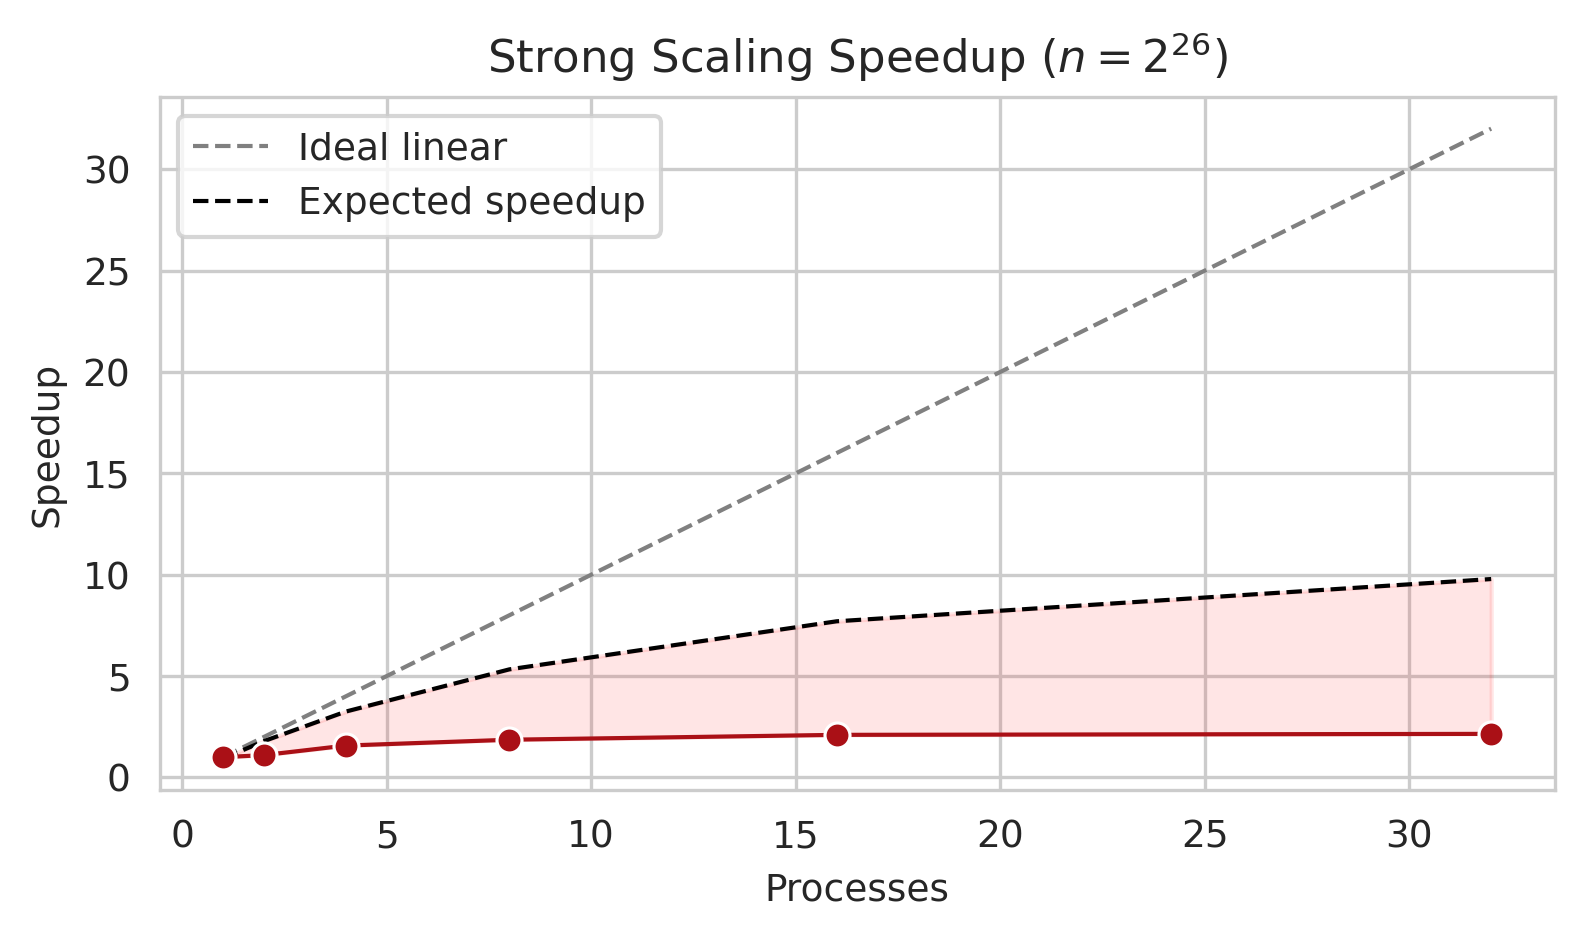

In [32]:
n_to_compare = max(mpi_df['n'])
mpi_strong_df = mpi_df[mpi_df["n"] == n_to_compare]
baseline = mpi_strong_df[mpi_strong_df["processes"] == 1]["time_ms"].values[0]

def strong_scaling(T):
    return (T * np.log2(n_to_compare)) / (np.log2(n_to_compare / T) + 2 * T)

processes = np.array(sorted(mpi_strong_df["processes"].unique()))
speedups = [baseline / mpi_strong_df[mpi_strong_df["processes"] == t]["time_ms"].values[0] for t in processes]

# optional: ideal speedup reference line
plt.plot(processes, processes, linestyle='--', color='gray', label='Ideal linear')
plt.plot(processes, strong_scaling(processes), linestyle='--', color='black', label='Expected speedup')

sns.lineplot(x=processes, y=speedups, marker='o', color=mpi_col[-1])

plt.fill_between(x=processes, y1=speedups, y2=strong_scaling(processes), alpha=0.1, color="red")

plt.xlabel("Processes")
plt.ylabel("Speedup")
plt.title(f"Strong Scaling Speedup ($n=2^{{{int(np.log2(n_to_compare))}}}$)")

plt.legend()
plt.show()